In [1]:
import os
import torch
import pandas as pd
import scanpy as sc
from sklearn import metrics
import multiprocessing as mp
from STWaveGraph.STWaveGraph import STWaveGraph
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

import matplotlib.pyplot as plt
import seaborn as sns

import os,sys
from pathlib import Path
from tqdm import tqdm
import warnings

In [2]:
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')
import rpy2

In [3]:
adata = sc.read_h5ad('/root/workspace/STWaveGraph-main copy/Data/raw/adata.h5ad')
adata.var_names_make_unique()

In [4]:
import torch
print("PyTorch版本:", torch.__version__)
print("CUDA是否可用:", torch.cuda.is_available())

PyTorch版本: 2.4.1+cu124
CUDA是否可用: True


<!-- 73:600:3500:random seed: 6497
6382:0.671
76:seed: 5549:0.603
510:seed: 8951:0.516 -->

In [7]:
model = STWaveGraph(
    adata=adata,
    n_clusters=7,
    device=device,

    # preprocessing
    n_top_genes=3000,
    pca_dim=30,

    # graph
    n_neighbors_spatial=8,
    expr_power=0.6,

    # model
    hidden_dim=64,
    proj_dim=32,
    n_bands=2,
    dropout=0.1,
    spectral_k=64,
    spectral_low_ratio=0.92,

    # training
    pretrain_epochs=300,
    finetune_epochs=120,
    lr=1e-3,
    finetune_lr=5e-4,
    weight_decay=1e-4,
    feature_mask_rate=0.05,
    feature_noise_std=0.03,
    regularization_warmup_epochs=20,

    # losses
    lambda_rec=0.30,
    lambda_ssl=1.0,
    lambda_smooth=0.15,
    lambda_kl=0.8,
    lambda_balance=0.01,
    lambda_boundary=0.02,
    boundary_margin=0.8,
    lambda_q_cons=0.3,

    # clustering
    cluster_method="mclust",
    cluster_pca_dim=8,
    mclust_model="EEE",
    mclust_fallback_to_gmm=True,
    refine_iters=4,

    random_seed=1219
)

adata = model.train(verbose=True)

========== Stage 1: Representation Pretraining ==========


100%|██████████| 300/300 [00:21<00:00, 14.16it/s]


========== Initialize Cluster Centers ==========
========== Stage 2: Clustering Finetuning ==========


 43%|████▎     | 52/120 [00:03<00:04, 13.70it/s]

[Finetune] Epoch 50/120 | loss=0.7412 | rec=1.5668 | ssl=0.2032 | smooth=0.2350 | kl=0.0370 | balance=0.0044 | bd=0.1453 | extra_reg_on=1


 85%|████████▌ | 102/120 [00:07<00:01, 13.23it/s]

[Finetune] Epoch 100/120 | loss=0.6927 | rec=1.4609 | ssl=0.1801 | smooth=0.2239 | kl=0.0469 | balance=0.0045 | bd=0.1487 | extra_reg_on=1


100%|██████████| 120/120 [00:08<00:00, 14.16it/s]


INFO: Using external clustering ('mclust') on embedding (h) for prediction.
fitting ...
  |======================================================================| 100%


In [12]:
adata

AnnData object with n_obs × n_vars = 1207 × 1020
    obs: 'cluster', 'celltype', 'pred_domain_raw', 'pred_domain'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'cluster_colors', 'hvg', 'log1p', 'use_q_for_pred', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

In [13]:
adata.obsm['emb']

array([[-0.10187741,  0.07514175, -0.25150442, ...,  0.09766812,
        -0.20485006, -0.07414636],
       [-0.01651144, -0.1749475 , -0.13611348, ..., -0.27780718,
         0.0644888 ,  0.06866576],
       [-0.04344499, -0.20658864, -0.13759586, ..., -0.31920227,
         0.02388647, -0.05953138],
       ...,
       [-0.05896664, -0.22498484, -0.11801557, ..., -0.31821227,
        -0.02317385, -0.01924711],
       [ 0.21665555, -0.17670761, -0.15759832, ..., -0.04272779,
        -0.33542928, -0.07137121],
       [-0.09081437, -0.2348163 , -0.02786948, ..., -0.28636318,
        -0.24311735, -0.00034911]], dtype=float32)

In [15]:
adata

AnnData object with n_obs × n_vars = 1207 × 1020
    obs: 'cluster', 'celltype', 'pred_domain_raw', 'pred_domain'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'cluster_colors', 'hvg', 'log1p', 'use_q_for_pred', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs', 'pred_domain_colors'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

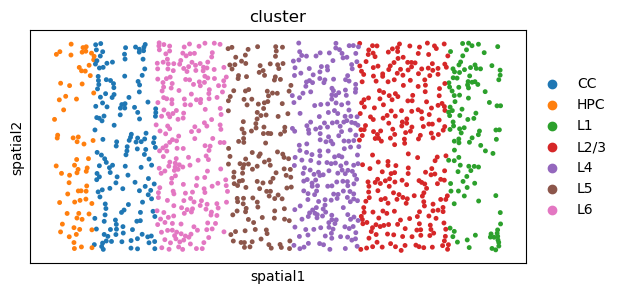

In [23]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["cluster"],
    title=["cluster"],
    spot_size=150,
    show=True
)

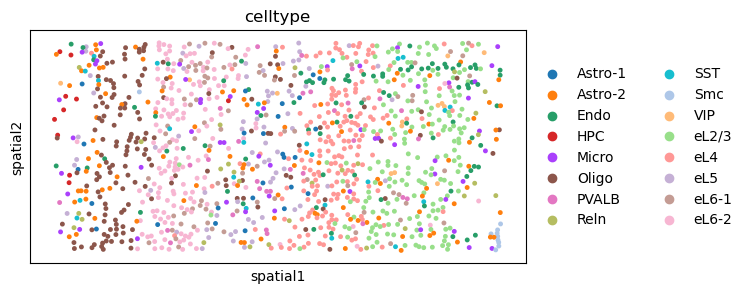

In [24]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["celltype"],
    title=["celltype"],
    spot_size=150,
    show=True
)

In [19]:
adata

AnnData object with n_obs × n_vars = 1207 × 1020
    obs: 'cluster', 'celltype', 'pred_domain_raw', 'pred_domain'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'cluster_colors', 'hvg', 'log1p', 'use_q_for_pred', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs', 'pred_domain_colors'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

In [20]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

true_labels = adata.obs['cluster']
predicted_labels = adata.obs['pred_domain']

ari_score = adjusted_rand_score(true_labels, predicted_labels)
nmi_score = normalized_mutual_info_score(true_labels, predicted_labels)

print(f"ARI Score: {ari_score:.4f}")
print(f"NMI Score: {nmi_score:.4f}")

ARI Score: 0.6502
NMI Score: 0.7198


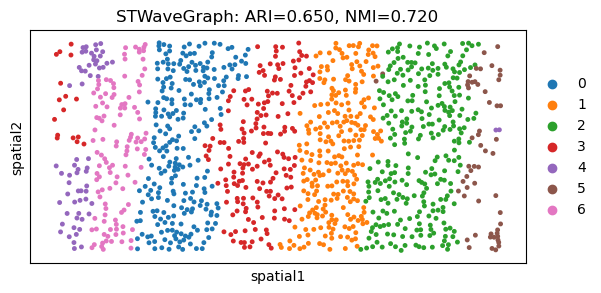

In [22]:
ARI=ari_score
NMI=nmi_score
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["pred_domain"],
    title=[f"STWaveGraph: ARI={ARI:.3f}, NMI={NMI:.3f}"],
    spot_size=150,
    show=True
)
